# Airbus 2nd round of requests

Compare holdings across CSDA STAC, ADAPT, and vendor archive at sites for sensors of interest.

| Author | Affiliation | Date |
| ---------------- | ---------------- | ---------------- |
| Paul Montesano, PhD | NASA Goddard Space Flight Center; ESSIC | Sept 2026 |

In [ ]:
#pip install contextily
#pip install matplotlib_scalebar

In [177]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from urllib.parse import quote
import numpy as np

import sys

# sys.path.append('/projects/code/csda_summaries/lib')
sys.path.append('/home/pmontesa/code/csda_summaries/lib')

import csdalib
import staclib
import siteslib

from datetime import datetime
from multiprocessing import Pool, cpu_count
from functools import partial
from tqdm import tqdm
import importlib

In [178]:
from pathlib import Path
STAC_CACHE_PATH = Path("/explore/nobackup/people/pmontesa/stac_cache")
STAC_CACHE_PATH.mkdir(parents=True, exist_ok=True)

## CSDA Evaluation Sites

Our database of `CSDA Evaluation Sites` is a critical & foundational set of information for CSDA SME work. Each site, uniquely identified with a `Site Name` and a specific geographic extent (AOI), provides some sort of radiometric or geometric reference for evaluation commercial imagery.

#### Read in our CSDA sites GeoJSON (AOIs) directly from GitHub

In [179]:
SITES_STR = 'csda' #'eval' #'csda'
SITES_FN = f'{SITES_STR}_sites_aoi.geojson'

In [180]:
# SITES_STR = 'hls_processed_tiles'
# SITES_FN = f'{SITES_STR}.geojson'

In [181]:
RAW_BASE = 'https://raw.githubusercontent.com/pahbs/csda_summaries/master'

sites_url = f'{RAW_BASE}/sites/{SITES_FN}'

sites_gdf = gpd.read_file(sites_url)
print(f"{sites_gdf.shape[0]} site AOIs, which are extents of various sizes and shapes, ranging from tiny corner reflector locations, to boxes and circles, to larger custom polygons.")

237 site AOIs, which are extents of various sizes and shapes, ranging from tiny corner reflector locations, to boxes and circles, to larger custom polygons.


In [182]:
#sites_gdf['Site Name'] = sites_gdf['Name_T']
#sites_gdf['geometry'] = sites_gdf.geometry.centroid

In [183]:
# SITES_STR = 'alaska_agb_validation'
# sites_gdf = gpd.read_file(f'../sites/{SITES_STR}_sites.geojson')
# sites_gdf['Site Name'] = sites_gdf['site_name']

In [184]:
BUF_KM = 0

In [185]:
DO_SITE_SUBSET = False
RADCALNET = False
DO_GLOBAL = False

In [186]:
if DO_SITE_SUBSET:
    if RADCALNET:
        SITES_STR = 'RadCalNet'
        sites_gdf = sites_gdf[sites_gdf.Source == SITES_STR]
    else:
        #SITENAME = 'Bonanza_Creek'
        # SITENAME = 'PICS Libya-4'
        SITENAME = 'Railroad Valley'
        SITES_STR = SITENAME.replace(' ','.')
        sites_gdf = sites_gdf[sites_gdf['Site Name'] == SITENAME]


# Table of CSDA STAC Collections

Here is what data we can find in the CSDA STAC

In [187]:
import pystac_client

# Define target CSDA STAC endpoint
STAC_URL = "https://csdap.earthdata.nasa.gov/stac"

try:
    # 1. Test API connection and structural validation
    print(f"Connecting to {STAC_URL}...")
    catalog = pystac_client.Client.open(STAC_URL)
    print(f"SUCCESS: Connected to API ID: {catalog.id}")
    #print(f"STAC Version supported: {catalog.stac_version}\n")
    
    # 2. Test the query engine by pulling a single item limit
    print("Testing search capabilities...")
    search = catalog.search(max_items=1)
    items = list(search.items())
    
    print(f"SUCCESS: Search engine returned {len(items)} record(s) correctly.")
    
except Exception as e:
    print(f"API ERROR: Connection or query parsing failed.\nDetails: {e}")


Connecting to https://csdap.earthdata.nasa.gov/stac...
SUCCESS: Connected to API ID: stac-fastapi
Testing search capabilities...
SUCCESS: Search engine returned 1 record(s) correctly.


In [188]:
import requests
from IPython.display import Markdown, display

STAC_API_URL = 'https://csdap.earthdata.nasa.gov/stac'

# Get collections
response = requests.get(f'{STAC_API_URL}/collections')
data = response.json()

collections = data.get('collections', [])

# Build markdown
markdown_output = f"# CSDA STAC Collections\n\n"
markdown_output += f"**Total Collections:** {len(collections)}\n\n"
markdown_output += "| ID | Title | Description | Temporal Coverage |\n"
markdown_output += "|:---|:---|:---|:---|\n"

for collection in collections:
    col_id = collection.get('id', 'N/A')
    title = collection.get('title', 'N/A')
    description = collection.get('description', 'N/A')
    
    # Truncate and clean description
    if description and description != 'N/A':
        description = description.replace('\n', ' ').replace('\r', '')
        if len(description) > 100:
            description = description[:100] + '...'
        description = description.replace('|', '\\|')
    
    # Get temporal extent with safe None checks
    temporal_str = 'N/A'
    try:
        extent = collection.get('extent')
        if extent and isinstance(extent, dict):
            temporal = extent.get('temporal')
            if temporal and isinstance(temporal, dict):
                intervals = temporal.get('interval', [])
                if intervals and isinstance(intervals, list) and len(intervals) > 0:
                    if intervals[0] and isinstance(intervals[0], list) and len(intervals[0]) > 0:
                        start = intervals[0][0] if intervals[0][0] else 'Unknown'
                        end = intervals[0][1] if len(intervals[0]) > 1 and intervals[0][1] else 'Present'
                        
                        # Format dates nicely
                        if isinstance(start, str) and start not in ['Unknown', 'N/A']:
                            start = start.split('T')[0]
                        if isinstance(end, str) and end not in ['Present', 'N/A']:
                            end = end.split('T')[0]
                        
                        temporal_str = f"{start} to {end}"
    except Exception as e:
        # If anything goes wrong, just leave as N/A
        pass
    
    # Create collection link
    collection_url = f"{STAC_API_URL}/collections/{col_id}"
    col_id_link = f"[{col_id}]({collection_url})"
    
    markdown_output += f"| {col_id_link} | {title} | {description} | {temporal_str} |\n"

# Display in notebook
display(Markdown(markdown_output))

# Save to file
with open(f'{STAC_CACHE_PATH}/stac_collections.md', 'w') as f:
    f.write(markdown_output)

print("\n✓ Saved to stac_collections.md")

# CSDA STAC Collections

**Total Collections:** 22

| ID | Title | Description | Temporal Coverage |
|:---|:---|:---|:---|
| [umbra](https://csdap.earthdata.nasa.gov/stac/collections/umbra) | Umbra | Umbra Space | 2023-11-02 to 2026-09-27 |
| [desis](https://csdap.earthdata.nasa.gov/stac/collections/desis) | DESIS | Teledyne Brown Engineering, Inc – DESIS | 2018-08-30 to 2024-05-25 |
| [pixxel](https://csdap.earthdata.nasa.gov/stac/collections/pixxel) | Pixxel | Pixxel | 2025-06-21 to 2026-06-13 |
| [satellogic](https://csdap.earthdata.nasa.gov/stac/collections/satellogic) | Satellogic | Satellogic Inc. | 2021-02-02 to 2026-09-26 |
| [planetiq](https://csdap.earthdata.nasa.gov/stac/collections/planetiq) | PlanetiQ | PlanetiQ | 2024-01-18 to 2025-03-24 |
| [geooptics](https://csdap.earthdata.nasa.gov/stac/collections/geooptics) | GeoOptics | geooptics | 2020-01-01 to 2021-04-30 |
| [iceye](https://csdap.earthdata.nasa.gov/stac/collections/iceye) | Iceye | ICEYE US | 2019-10-17 to 2026-09-28 |
| [spire](https://csdap.earthdata.nasa.gov/stac/collections/spire) | Spire | Spire | 2019-11-01 to 2025-08-09 |
| [airbus-dem](https://csdap.earthdata.nasa.gov/stac/collections/airbus-dem) | Airbus - DEM | Airbus - DEM | 2025-09-19 to 2026-04-13 |
| [tomorrow](https://csdap.earthdata.nasa.gov/stac/collections/tomorrow) | Tomorrow | The Tomorrow Companies Inc. | 2023-06-24 to 2026-02-22 |
| [pgc-earthdem](https://csdap.earthdata.nasa.gov/stac/collections/pgc-earthdem) | EarthDEM | EarthDEM | 2002-02-06 to 2024-07-01 |
| [maxar-sdx](https://csdap.earthdata.nasa.gov/stac/collections/maxar-sdx) | Maxar DEM | Maxar Technologies – Precision 3D | 2008-01-18 to 2025-05-26 |
| [capellaspace](https://csdap.earthdata.nasa.gov/stac/collections/capellaspace) | CapellaSpace | capellaspace | 2020-12-26 to 2026-09-27 |
| [airbus](https://csdap.earthdata.nasa.gov/stac/collections/airbus) | Airbus U.S.- SAR | Airbus U.S. | 2007-11-19 to 2026-08-20 |
| [maxar-legion](https://csdap.earthdata.nasa.gov/stac/collections/maxar-legion) | Maxar Legion | Maxar Technologies Inc. | 2024-09-11 to 2026-09-21 |
| [ghgsat](https://csdap.earthdata.nasa.gov/stac/collections/ghgsat) | GHGSat | GHGSat | 2021-01-03 to 2026-09-26 |
| [airbus-optical](https://csdap.earthdata.nasa.gov/stac/collections/airbus-optical) | Airbus U.S.- Optical | Airbus U.S.- Optical | 2021-08-15 to 2026-09-25 |
| [blacksky](https://csdap.earthdata.nasa.gov/stac/collections/blacksky) | BlackSky | BlackSky Technology, Inc. | 2019-05-07 to 2026-08-17 |
| [kuvaspace](https://csdap.earthdata.nasa.gov/stac/collections/kuvaspace) | kuvaspace | Kuva Space | Unknown to Present |
| [planet](https://csdap.earthdata.nasa.gov/stac/collections/planet) | Planet | Planet | 2009-03-09 to 2026-07-18 |
| [mda](https://csdap.earthdata.nasa.gov/stac/collections/mda) | MDA | MDA Space | Unknown to Present |
| [hydrosat](https://csdap.earthdata.nasa.gov/stac/collections/hydrosat) | hydrosat | HydroSat | 2025-09-29 to 2025-09-29 |



✓ Saved to stac_collections.md


### Create site dicts for all sites

In [189]:
def create_global_grid(grid_size=30):
    """
    Create a grid of sub-regions covering the globe.
    
    Parameters:
    -----------
    grid_size : int
        Size of each grid cell in degrees (default 30° = 12x6 grid)
    
    Returns:
    --------
    dict : Dictionary of site_dicts for each grid cell
    """
    site_dicts = {}
    
    # Create grid from -180 to 180 longitude, -90 to 90 latitude
    lons = range(-180, 180, grid_size)
    lats = range(-90, 90, grid_size)
    
    for i, lon_start in enumerate(lons):
        for j, lat_start in enumerate(lats):
            lon_end = min(lon_start + grid_size, 180)
            lat_end = min(lat_start + grid_size, 90)
            
            # Create unique name for this grid cell
            grid_name = f"grid_{i:02d}_{j:02d}"
            
            # Calculate center point
            center_lon = (lon_start + lon_end) / 2
            center_lat = (lat_start + lat_end) / 2
            
            site_dicts[grid_name] = {
                'bbox': [lon_start, lat_start, lon_end, lat_end],
                'lon': center_lon,
                'lat': center_lat,
                'buffer': None,
                'geom_type': 'Polygon'
            }
    
    return site_dicts

In [190]:
# Usage in your code:
if DO_GLOBAL:
    # Global search - break into grid
    SITENAME = 'Global'
    SITES_STR = SITENAME.replace(' ', '.')
    
    # Create grid (adjust grid_size as needed: 30°, 20°, 10°, etc.)
    site_dicts = create_global_grid(grid_size=10)  # 30° = 12x6 = 72 regions
    
    print(f"Global search broken into {len(site_dicts)} sub-regions")
else:
    site_dicts = staclib.create_site_dict_from_gdf(sites_gdf, site_name_field='Site Name', buffer_degrees=0)

# Convert to list of tuples for processing
CSDA_EVAL_SITE_ITEMS = list(site_dicts.items())

In [191]:
len(site_dicts)

224

# Multiprocess search across all CSDA Evaluation Sites for a vendor

### Configure search

In [192]:
TODAY = datetime.now().strftime('%Y-%m-%d')
START_OF_COMMERCIAL_ERA = '1999-01-01'

In [193]:
# Misc search
COLLECTION_LIST = ['airbus-optical']
YEAR = 'allyears'
START_DATE = START_OF_COMMERCIAL_ERA
# YEAR = 2024
# START_DATE = f'{YEAR}-01-01'
END_DATE = TODAY
#END_DATE = '2019-12-31'
MONTH_LIST = list(range(1,12+1))

In [194]:
CSDA_EVAL_SITE_ITEMS = list(site_dicts.items())

### Multiprocess SDX search across CSDA Eval sites

In [195]:
import importlib
importlib.reload(staclib)

<module 'staclib' from '/home/pmontesa/code/csda_summaries/lib/staclib.py'>

In [196]:
search_func = partial(staclib.stac_search_site, end_date=END_DATE, start_date=START_DATE,  months=MONTH_LIST,
                      collections=COLLECTION_LIST
                     )
#search_func = partial(search_site, today=today, start_date='2010-01-01', collections=['maxar'])

n_processes = max(1, cpu_count() - 4)
print(f"Using {n_processes} processes to search {len(CSDA_EVAL_SITE_ITEMS)} sites\n")

# Run with progress bar
with Pool(processes=n_processes) as pool:
    results = list(tqdm(
        pool.imap(search_func, CSDA_EVAL_SITE_ITEMS),
        total=len(CSDA_EVAL_SITE_ITEMS),
        desc="Searching sites"
    ))

# Collect and report results
stac_gdf_list = []
stac_items_list = []
print("\nResults by site:")
for site_name, gdf, items, message in results:
    print(f"  {site_name}: {message}")
    if gdf is not None:
        stac_gdf_list.append(gdf)
        stac_items_list.extend(items)

# Combine
if stac_gdf_list:
    stac_gdf = pd.concat(stac_gdf_list, ignore_index=True)
    print(f"\n{'='*60}")
    print(f"Total: {len(stac_gdf)} items from {stac_gdf['site_name'].nunique()} sites")
    print(f"{'='*60}")
    print("\nItems per site:")
    print(stac_gdf['site_name'].value_counts())
else:
    print("\nNo items found")
    stac_gdf = gpd.GeoDataFrame()

Using 36 processes to search 224 sites



Searching sites: 100%|██████████| 224/224 [00:18<00:00, 12.29it/s]



Results by site:
  Baoshan: No items found
  Cairns: No items found
  Copiapo: No items found
  Luanda: No items found
  Manta: No items found
  Mexico City: No items found
  Mogadishu: No items found
  Perth: No items found
  Albuquerque: Found 10 items across 28 interval(s) (months=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12])
  Amazon: No items found
  Baotou: Found 14 items across 28 interval(s) (months=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12])
  Atacama Desert: No items found
  Belo Horizonte: No items found
  Boston: Found 48 items across 28 interval(s) (months=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12])
  Kansas City: No items found
  San Diego: No items found
  Los Angeles: No items found
  Novosibirsk: No items found
  Konya-airport: No items found
  Konya-city: No items found
  Mansoura: No items found
  Cape Town: No items found
  Casablanca: No items found
  Caspian Sea: No items found
  Catania: No items found
  Crater Lake: No items found
  Cuprite: No items found
  Antarctica GP

In [197]:
#ic[100].assets
stac_gdf.shape

(596, 678)

## Save items & footprints: 

SDX STAC search results to JSON & geopackage

In [198]:
stac_gdf = stac_gdf.drop(columns=[col for col in stac_gdf.columns if 'asset' in col])

# Convert list columns to strings
stac_gdf_copy = stac_gdf.copy()
for col in stac_gdf_copy.columns:
    if stac_gdf_copy[col].apply(lambda x: isinstance(x, list)).any():
        stac_gdf_copy[col] = stac_gdf_copy[col].apply(lambda x: str(x) if isinstance(x, list) else x)
        
stac_gdf_copy.to_parquet(str(STAC_CACHE_PATH / f"stac_{SITES_STR}_{'_'.join(COLLECTION_LIST)}_{YEAR}.parquet"))

In [199]:
from pystac import ItemCollection

ic = ItemCollection(stac_items_list)
ic.save_object(str(STAC_CACHE_PATH / f"stac_items_{SITES_STR}_{'_'.join(COLLECTION_LIST)}_{YEAR}.json"))

In [200]:
import pandas as pd
import numpy as np

# IMPORTANT: if `ic` came from a pystac_client search (an iterator), it is single-use.
# Materialize it once so repeated analysis doesn't silently return zero items.
items = list(ic)
n_items = len(items)
print(f"{n_items} items")

def _asset_size(asset):
    """Robust size lookup across pystac versions / missing file extension."""
    try:
        return asset.ext.file.size            # pystac >= 1.9 accessor style
    except Exception:
        pass
    try:
        from pystac.extensions.file import FileExtension
        return FileExtension.ext(asset).size  # older style
    except Exception:
        return asset.extra_fields.get("file:size")  # raw field fallback

records = []
for it in items:
    props = it.properties or {}
    for key, asset in it.assets.items():
        records.append({
            "item_id":     it.id,
            "collection":  getattr(it, "collection_id", None),
            # adjust these to whatever your provider uses; missing keys just become None
            "item_type":   props.get("item_type") or props.get("platform"),
            "datetime":    props.get("datetime"),
            "asset_key":   key,
            "roles":       tuple(asset.roles or ()),
            "media_type":  asset.media_type,
            "size_bytes":  _asset_size(asset),
        })

assets_df = pd.DataFrame(records)
assets_df["datetime"] = pd.to_datetime(assets_df["datetime"], errors="coerce", utc=True)
print(assets_df.shape)
assets_df.tail()

596 items
(9989, 8)


,item_id,collection,item_type,datetime,asset_key,roles,media_type,size_bytes
9984,PHR1A_202509091824204_MS_ORT_RFL,airbus-optical,PHR1A,2025-09-09 18:24:20.400000+00:00,area-of-interest-mask,"(auxiliary,)",application/gml+xml,1542
9985,PHR1A_202509091824204_MS_ORT_RFL,airbus-optical,PHR1A,2025-09-09 18:24:20.400000+00:00,detector-quality-mask,"(auxiliary,)",application/gml+xml,649
9986,PHR1A_202509091824204_MS_ORT_RFL,airbus-optical,PHR1A,2025-09-09 18:24:20.400000+00:00,technical-quality-mask,"(auxiliary,)",application/gml+xml,632
9987,PHR1A_202509091824204_MS_ORT_RFL,airbus-optical,PHR1A,2025-09-09 18:24:20.400000+00:00,saturation-quality-mask,"(auxiliary,)",application/gml+xml,713
9988,PHR1A_202509091824204_MS_ORT_RFL,airbus-optical,PHR1A,2025-09-09 18:24:20.400000+00:00,visibility-quality-mask,"(auxiliary,)",application/gml+xml,640


In [201]:
import pandas as pd

GROUP_KEYS = ["item_id", "item_type", "datetime"]

# dropna=False keeps items whose item_type or datetime is missing (otherwise they vanish)
item_summary = (
    assets_df.groupby(GROUP_KEYS, dropna=False)
    .agg(
        collection      = ("collection", lambda s: ", ".join(sorted(s.dropna().unique())) or None),
        n_assets        = ("asset_key", "nunique"),
        total_bytes     = ("size_bytes", "sum"),
        n_assets_sized  = ("size_bytes", "count"),          # how many reported file:size
        n_media_types   = ("media_type", "nunique"),
        asset_keys      = ("asset_key", lambda s: ", ".join(sorted(s.unique()))),
        roles           = ("roles", lambda s: ", ".join(sorted({r for t in s for r in t}))),
    )
    .reset_index()
)

# Flag whether size data is complete for the item (total_bytes is a lower bound if not)
item_summary["size_complete"] = item_summary["n_assets_sized"] == item_summary["n_assets"]

# Human-readable size + bundle signature for grouping identical items
try:
    import humanize
    item_summary["total_size"] = item_summary["total_bytes"].apply(
        lambda b: humanize.naturalsize(b) if pd.notna(b) and b > 0 else "—")
except ImportError:
    item_summary["total_size"] = (item_summary["total_bytes"] / 1e9).round(3).astype(str) + " GB"

item_summary["bundle_id"] = item_summary["asset_keys"].factorize()[0]

item_summary = item_summary.sort_values("datetime").reset_index(drop=True)

print(f"{len(item_summary)} unique (item_id, item_type, datetime) combinations")
print(f"{item_summary['item_id'].nunique()} unique item_ids  "
      f"→ {'1:1' if len(item_summary) == item_summary['item_id'].nunique() else '⚠️ duplicated item_ids'}")
print(f"{item_summary['bundle_id'].nunique()} distinct asset bundles")

display(item_summary[["item_id", "item_type", "datetime", "collection",
                      "n_assets", "total_size", "size_complete", "bundle_id"]])

492 unique (item_id, item_type, datetime) combinations
492 unique item_ids  → 1:1
104 distinct asset bundles


,item_id,item_type,datetime,collection,n_assets,total_size,size_complete,bundle_id
0,PNEO3_202108150346132_PAN_ORT_RFL,PNEO3,2021-08-15 03:46:13.200000+00:00,airbus-optical,8,2.963 GB,True,4
1,PNEO3_202108150346132_MS-FS_ORT_RFL,PNEO3,2021-08-15 03:46:13.200000+00:00,airbus-optical,11,1.112 GB,True,3
2,PNEO3_202108220915001_PAN_ORT_SR,PNEO3,2021-08-22 09:15:00.100000+00:00,airbus-optical,15,7.235 GB,True,8
3,PNEO3_202108220915001_PAN_ORT_BAS,PNEO3,2021-08-22 09:15:00.100000+00:00,airbus-optical,10,7.124 GB,True,7
4,PNEO3_202108220915001_MS-FS_ORT_SR,PNEO3,2021-08-22 09:15:00.100000+00:00,airbus-optical,22,2.783 GB,True,6
...,...,...,...,...,...,...,...,...
487,PHR1B_202603160337039_MS_ORT_RFL,PHR1B,2026-03-16 03:37:03.900000+00:00,airbus-optical,18,0.845 GB,True,0
488,PNEO3_202603191100452_MS_ORT_RFL,PNEO3,2026-03-19 11:00:45.200000+00:00,airbus-optical,10,1.202 GB,True,16
489,PNEO3_202603191100452_PAN_ORT_RFL,PNEO3,2026-03-19 11:00:45.200000+00:00,airbus-optical,10,4.805 GB,True,16
490,PHR1B_202603221102215_P_ORT_RFL,PHR1B,2026-03-22 11:02:21.500000+00:00,airbus-optical,18,3.697 GB,True,0


In [202]:
import pandas as pd

s = item_summary["item_id"].str.split("_", n=2, expand=True)
item_summary["acquisition_id"] = s[0] + "_" + s[1]
item_summary["product"] = s[2]

acquisitions = (
    item_summary.groupby(["acquisition_id", "item_type", "datetime", "collection"],
                         as_index=False)
    .agg(n_products=("product", "nunique"),
         products=("product", lambda x: sorted(x.dropna().unique())),
         n_assets=("n_assets", "sum"),
         total_gb=("total_bytes", lambda b: round(b.sum() / 1e9, 3)))
    .sort_values("datetime")
    .reset_index(drop=True)
)

print(f"{len(item_summary)} items → {len(acquisitions)} acquisitions")
acquisitions

492 items → 200 acquisitions


,acquisition_id,item_type,datetime,collection,n_products,products,n_assets,total_gb
0,PNEO3_202108150346132,PNEO3,2021-08-15 03:46:13.200000+00:00,airbus-optical,2,"[MS-FS_ORT_RFL, PAN_ORT_RFL]",19,4.075
1,PNEO3_202108220915001,PNEO3,2021-08-22 09:15:00.100000+00:00,airbus-optical,4,"[MS-FS_ORT_BAS, MS-FS_ORT_SR, PAN_ORT_BAS, PAN...",63,19.814
2,PNEO3_202111080914549,PNEO3,2021-11-08 09:14:54.900000+00:00,airbus-optical,4,"[MS-FS_ORT_BAS, MS-FS_ORT_SR, PAN_ORT_BAS, PAN...",63,19.730
3,PNEO4_202201170911126,PNEO4,2022-01-17 09:11:12.600000+00:00,airbus-optical,4,"[MS-FS_ORT_BAS, MS-FS_ORT_SR, PAN_ORT_BAS, PAN...",63,19.774
4,PNEO4_202203101536245,PNEO4,2022-03-10 15:36:24.500000+00:00,airbus-optical,2,"[MS-FS_ORT_RFL, PAN_ORT_RFL]",38,13.138
...,...,...,...,...,...,...,...,...
195,PNEO4_202603050911357,PNEO4,2026-03-05 09:11:35.700000+00:00,airbus-optical,4,"[MS-FS_ORT_BAS, MS-FS_ORT_SR, PAN_ORT_BAS, PAN...",51,13.967
196,PNEO3_202603141104171,PNEO3,2026-03-14 11:04:17.100000+00:00,airbus-optical,2,"[MS_ORT_RFL, PAN_ORT_RFL]",22,6.007
197,PHR1B_202603160337039,PHR1B,2026-03-16 03:37:03.900000+00:00,airbus-optical,2,"[MS_ORT_RFL, P_ORT_RFL]",36,4.229
198,PNEO3_202603191100452,PNEO3,2026-03-19 11:00:45.200000+00:00,airbus-optical,2,"[MS_ORT_RFL, PAN_ORT_RFL]",20,6.007


## Read in local footprints

In [203]:
footprints_gdf = gpd.read_file('/home/pmontesa/CSDA_eval/footprints/footprints_CSDA_eval_ACQUISITIONS_unique_2026-09-10.gpkg')
footprints_gdf = footprints_gdf[footprints_gdf.affiliation == 'Airbus']
footprints_gdf.head()

,acquisition_datetime,affiliation,constellation,sensor,image_type,product_level,cloud_percent,gsd,acquisition_id,file_path,...,radiometric_type,_needs_raster_footprint,product_type,sensor_image_id,sites,Site_Primary,Site_Secondary,Site_Tertiary,num_sites,geometry
82,2021-08-15T03:46:13.890548+00:00,Airbus,Pleiades Neo,PNEO3,"P, MS",ORTHO,0.012944612805016478,1.3000160455703735,ACQ_PNEO3_00507100187587,/explore/nobackup/projects/CSDA_eval/Data/Airb...,...,REFLECTANCE,1,nan,None,Baotou,Baotou,None,None,1,"POLYGON ((109.55139 40.81733, 109.54967 40.896..."
83,2021-08-22T09:15:01.762430+00:00,Airbus,Pleiades Neo,PNEO3,"P, MS",ORTHO,0,1.2114133834838867,ACQ_PNEO3_00517800223246,/explore/nobackup/projects/CSDA_eval/Data/Airb...,...,"BASIC, SURFACE_REFLECTANCE",1,nan,None,PICS Libya-4,PICS Libya-4,None,None,1,"POLYGON ((23.31024 28.65089, 23.40446 28.64925..."
84,2021-11-08T09:14:56.520089+00:00,Airbus,Pleiades Neo,PNEO3,"P, MS",ORTHO,0,1.207618236541748,ACQ_PNEO3_00817800762442,/explore/nobackup/projects/CSDA_eval/Data/Airb...,...,"BASIC, SURFACE_REFLECTANCE",1,nan,None,PICS Libya-4,PICS Libya-4,None,None,1,"POLYGON ((23.31059 28.65040, 23.40482 28.64876..."
85,2022-04-13T09:15:09.761134+00:00,Airbus,Pleiades Neo,PNEO3,"P, MS",ORTHO,0,1.2262132167816162,ACQ_PNEO3_01417802079177,/explore/nobackup/projects/CSDA_eval/Data/Airb...,...,"BASIC, SURFACE_REFLECTANCE",1,nan,None,PICS Libya-4,PICS Libya-4,None,None,1,"POLYGON ((23.30947 28.65226, 23.40369 28.65062..."
86,2022-08-26T15:36:10.739262+00:00,Airbus,Pleiades Neo,PNEO3,"P, MS",ORTHO,0,1.3109210729599,ACQ_PNEO3_01925603746292,/explore/nobackup/projects/CSDA_eval/Data/Airb...,...,REFLECTANCE,1,nan,None,Boston,Boston,None,None,1,"POLYGON ((-71.10157 42.34902, -71.10434 42.431..."


## Read in archive results 

In [204]:
SHEET_ID = "16VopHRqlt5qbl4HgZdkVLUIHLVi9lZWPLJMY-QWsJ8g"
GID      = "686545659"
url = f"https://docs.google.com/spreadsheets/d/{SHEET_ID}/export?format=csv&gid={GID}"

archive_df = pd.read_csv(url)

print(archive_df.shape)
print(archive_df.columns.tolist())
archive_df.tail()

(1033, 9)
['Site Name', 'location_name', 'country', 'longitude', 'latitude', 'acquisitionDate', 'acquisitionIdentifier', 'platform', 'cloudCover']


,Site Name,location_name,country,longitude,latitude,acquisitionDate,acquisitionIdentifier,platform,cloudCover
1028,Valencia,"ESP-VLC2, El Palmar",Spain,-0.3263,39.2979,2025-03-25T10:50:28.930Z,DS_PHR1B_202503251050289_FR1_PX_W001N39_0809_0...,PHR1B,4.958361
1029,Valencia,"ESP-VLC2, El Palmar",Spain,-0.3263,39.2979,2025-03-30T11:01:28.805Z,DS_PHR1B_202503301101288_FR1_PX_W001N39_0811_0...,PHR1B,0.000000
1030,Valencia,"ESP-VLC2, El Palmar",Spain,-0.3263,39.2979,2025-07-31T11:05:44.555Z,DS_PHR1B_202507311105445_FR1_PX_W001N39_0811_0...,PHR1B,0.051507
1031,Valencia,"ESP-VLC2, El Palmar",Spain,-0.3263,39.2979,2026-07-06T10:50:48.180Z,DS_PHR1B_202607061050481_FR1_PX_W001N39_0801_0...,PHR1B,0.000000
1032,WLEF,WLEF tower,USA,-90.2732,45.9449,2023-11-13T17:05:49.056Z,DS_PHR1A_202311131705490_FR1_PX_W091N46_1006_0...,PHR1A,0.000000


In [205]:
TOL = pd.Timedelta("5s")

def norm_sensor(s):
    return s.astype(str).str.upper().str.replace(r"[\s_\-]", "", regex=True)

# --- STAC acquisitions -----------------------------------------------------
stac = pd.DataFrame({
    "source":   "STAC",
    "uid":      acquisitions["acquisition_id"].values,
    "sensor":   norm_sensor(acquisitions["item_type"]).values,
    "datetime": pd.to_datetime(acquisitions["datetime"], utc=True).values,
    "site":     None,                     # see Cell 1b
    "detail":   acquisitions["products"].map(", ".join).values,
})

# --- local footprints ------------------------------------------------------
local = pd.DataFrame({
    "source":   "LOCAL",
    "uid":      footprints_gdf["acquisition_id"].values,
    "sensor":   norm_sensor(footprints_gdf["sensor"]).values,
    "datetime": pd.to_datetime(footprints_gdf["acquisition_datetime"], utc=True).values,
                               #format="mixed").values,
    "site":     footprints_gdf["Site_Primary"].values,
    "detail":   footprints_gdf["product_level"].astype(str).values,
})

# --- vendor archive (one row per site-hit -> collapse to one per acquisition)
arch = (archive_df.assign(_s=archive_df["Site Name"])
        .groupby("acquisitionIdentifier", as_index=False)
        .agg(datetime=("acquisitionDate", "first"),
             sensor=("platform", "first"),
             site=("_s", lambda s: ", ".join(sorted(s.dropna().unique()))),
             cloud=("cloudCover", "first")
            )
       )
archive = pd.DataFrame({
    "source":   "ARCHIVE",
    "uid":      arch["acquisitionIdentifier"].values,
    "sensor":   norm_sensor(arch["sensor"]).values,
    "datetime": pd.to_datetime(arch["datetime"], utc=True).values,
    "site":     arch["site"].values,
    "detail":   "cloud=" + arch["cloud"].astype(str),
})

long = pd.concat([stac, local, archive], ignore_index=True)
print(long.groupby("source").size(), "\n")
print(long.groupby(["source", "sensor"]).size())   # ← check sensors actually overlap

source
ARCHIVE    1033
LOCAL       191
STAC        200
dtype: int64 

source   sensor
ARCHIVE  PHR1A      64
         PHR1B      51
         PNEO3     323
         PNEO4     317
         SPOT6     278
LOCAL    PHR1A      40
         PHR1B      33
         PNEO3      44
         PNEO4      40
         SPOT6      34
STAC     PHR1A      39
         PHR1B      33
         PNEO3      52
         PNEO4      44
         SPOT6      32
dtype: int64


In [206]:
sj = (stac_gdf.to_crs(4326).sjoin(sites_gdf.to_crs(4326)[["Site Name", "geometry"]],
                                  how="inner", predicate="intersects")
      .groupby("id")["Site Name"].agg(lambda s: ", ".join(sorted(set(s)))))
# map via the representative item_id in your acquisitions table
stac_site = acquisitions.set_index("acquisition_id")["representative_item_id"].map(sj) \
            if "representative_item_id" in acquisitions else None

In [207]:
long = long.sort_values(["sensor", "datetime"]).reset_index(drop=True)
gap = long.groupby("sensor")["datetime"].diff() > TOL
long["match_id"] = long["sensor"] + "_" + gap.groupby(long["sensor"]).cumsum().astype(str)

presence = (long.assign(v=1).pivot_table(index="match_id", columns="source",
                                         values="v", aggfunc="max", fill_value=0)
            .reindex(columns=["STAC", "LOCAL", "ARCHIVE"], fill_value=0).astype(bool))

info = (long.groupby("match_id")
        .agg(sensor=("sensor", "first"),
             datetime=("datetime", "min"),
             span_s=("datetime", lambda s: (s.max() - s.min()).total_seconds()),
             sites=("site", lambda s: ", ".join(sorted({x for v in s.dropna()
                                                        for x in str(v).split(", ")})) or None),
             uids=("uid", lambda s: " | ".join(s))))

m = info.join(presence)
m["status"] = [
    "have_local_and_stac" if l and s else
    "local_only"          if l else
    "stac_only_download"  if s else
    "archive_only_ORDER"
    for s, l in zip(m["STAC"], m["LOCAL"])
]
m = m.sort_values("datetime")

print(f"{len(long)} records → {len(m)} unique acquisitions")
m["status"].value_counts()

1424 records → 976 unique acquisitions


archive_only_ORDER     777
have_local_and_stac    181
stac_only_download      10
local_only               8
Name: status, dtype: int64

In [208]:
# 1. what to order (in vendor archive, not local, not on STAC)
to_order = (m.query("status == 'archive_only_ORDER'")
            .reset_index()[["match_id", "sensor", "datetime", "sites", "uids"]])
print(f"→ ORDER {len(to_order)} acquisitions")
display(to_order)

# 2. on STAC but not downloaded yet
display(m.query("status == 'stac_only_download'")[["sensor", "datetime", "sites"]])

# 3. local but not findable in STAC or archive (check your sensor/time normalization)
display(m.query("status == 'local_only'")[["sensor", "datetime", "sites", "uids"]])

# 4. site × status matrix
site_status = (m.reset_index().assign(site=m["sites"].fillna("Unknown").values)
               .assign(site=lambda d: d["site"].str.split(", ")).explode("site")
               .pivot_table(index="site", columns="status", values="match_id",
                            aggfunc="count", fill_value=0))
display(site_status)

# 5. tolerance sensitivity — is 5s stable?
for t in ["1s", "5s", "10s", "30s"]:
    g = long.groupby("sensor")["datetime"].diff() > pd.Timedelta(t)
    n = (long["sensor"] + "_" + g.groupby(long["sensor"]).cumsum().astype(str)).nunique()
    print(f"  {t:>4} → {n} acquisitions")

→ ORDER 777 acquisitions


,match_id,sensor,datetime,sites,uids
0,PNEO3_8,PNEO3,2023-04-01 09:17:42.084,Gobabeb,ACQ_CP_PNEO3_028015_0000573280_ST_0-21 | ACQ_P...
1,PNEO3_9,PNEO3,2023-04-01 09:17:59.079,Gobabeb,ACQ_PNEO3_02801506513510
2,PNEO4_5,PNEO4,2023-04-04 09:11:24.233,PICS Libya-4,ACQ_PNEO4_02725206553683
3,SPOT6_0,SPOT6,2023-04-04 10:21:21.874,Valencia,DS_SPOT6_202304041021219_FR1_FR1_SV1_SV1_E000N...
4,PHR1A_0,PHR1A,2023-04-05 09:17:38.305,Gobabeb,DS_PHR1A_202304050917383_FR1_PX_E015S24_0110_0...
...,...,...,...,...,...
772,PNEO4_262,PNEO4,2026-09-18 18:40:53.186,Railroad Valley,ACQ_PNEO4_07609507561613
773,PNEO3_265,PNEO3,2026-09-21 09:21:10.845,Gobabeb,ACQ_CP_PNEO3_076326_0001610312_ST_0-54 | ACQ_P...
774,PNEO3_266,PNEO3,2026-09-21 09:21:23.829,Gobabeb,ACQ_CP_PNEO3_076326_0001610313_ST_0-22 | ACQ_P...
775,PNEO3_267,PNEO3,2026-09-21 09:21:41.837,Gobabeb,ACQ_PNEO3_07632607600777


,sensor,datetime,sites
match_id,,,
PNEO3_3,PNEO3,2022-03-31 03:31:27.700,None
PNEO4_3,PNEO4,2022-10-12 03:31:18.400,None
PNEO3_7,PNEO3,2023-01-08 15:32:46.000,None
PNEO3_72,PNEO3,2023-10-04 03:46:13.434,Baotou
PNEO4_105,PNEO4,2024-08-13 03:34:53.573,Baotou
PHR1B_24,PHR1B,2025-08-23 10:37:51.300,None
PHR1B_26,PHR1B,2025-08-23 10:38:33.100,None
PHR1A_72,PHR1A,2025-12-30 10:45:27.600,None
PHR1A_74,PHR1A,2025-12-30 10:46:07.500,None


,sensor,datetime,sites,uids
match_id,,,,
PHR1A_13,PHR1A,2024-08-31 17:59:08.531000,Not CSDA Eval Site,DS_PHR1A_202408311759075_FR1_PX_W106N40_1014_0...
PNEO3_123,PNEO3,2025-04-11 17:56:02.999800,Not CSDA Eval Site,ACQ_PNEO3_05621316412341
PHR1B_22,PHR1B,2025-08-23 10:35:23.000000,Salon-de-Provence,DS_PHR1B_202508231037513_FR1_PX_E005N43_0215_0...
PHR1B_23,PHR1B,2025-08-23 10:36:23.000000,Salon-de-Provence,DS_PHR1B_202508231038331_FR1_PX_E005N43_0215_0...
PNEO4_167,PNEO4,2025-08-30 09:15:01.288214,Not CSDA Eval Site,ACQ_PNEO4_06117802002035
PNEO4_171,PNEO4,2025-09-01 17:57:00.469828,Not CSDA Eval Site,ACQ_PNEO4_06121302041467
PHR1A_70,PHR1A,2025-12-30 10:43:23.000000,Salon-de-Provence,DS_PHR1A_202512301045276_FR1_PX_E005N43_0215_0...
PHR1A_71,PHR1A,2025-12-30 10:43:53.000000,Salon-de-Provence,DS_PHR1A_202512301046075_FR1_PX_E005N43_0215_0...


status,archive_only_ORDER,have_local_and_stac,local_only,stac_only_download
site,,,,
AZ Maricopa Pinal,0,3,0,0
Albuquerque,0,7,0,0
Baotou,185,3,0,2
Boston,0,20,0,0
Etang de Berre,0,7,0,0
Gobabeb,322,16,0,0
Golmud,6,0,0,0
La Crau,51,17,0,0
London,0,15,0,0


    1s → 1046 acquisitions
    5s → 976 acquisitions
   10s → 963 acquisitions
   30s → 678 acquisitions


In [209]:
TOL = pd.Timedelta("5s")

def to_utc(s):
    """Always return tz-aware UTC datetimes, regardless of input tz-awareness."""
    d = pd.to_datetime(pd.Series(s).reset_index(drop=True), utc=True, errors="coerce")
    return d

def norm_sensor(s):
    return pd.Series(s).astype(str).str.upper().str.replace(r"[\s_\-]", "", regex=True)

# --- STAC: acquisition_id -> list of item URLs ----------------------------
def item_url(it):
    href = it.get_self_href()
    if href:
        return href
    # fallback: the primary raster asset href (strip any signing query string)
    for k in ("basic_analytic_8b", "ortho_analytic_8b", "visual"):
        if k in it.assets:
            return it.assets[k].href.split("?")[0]
    return next(iter(it.assets.values())).href.split("?")[0] if it.assets else None

stac_urls = {}
for it in items:
    parts = str(it.id).split("_")
    acq = "_".join(parts[:2])                    # same split used to build `acquisitions`
    stac_urls.setdefault(acq, []).append(item_url(it))

stac_ref = pd.DataFrame({
    "sensor":   norm_sensor(acquisitions["item_type"]),
    "datetime": pd.to_datetime(acquisitions["datetime"], utc=True),
    "loc":      acquisitions["acquisition_id"].map(lambda a: stac_urls.get(a, [])),
})

# --- LOCAL: one row per acquisition_id -> list of file paths ---------------
fp = footprints_gdf.reset_index(drop=True)
loc_ref = (fp.assign(_sensor=norm_sensor(fp["sensor"]),
                     _dt=to_utc(fp["acquisition_datetime"]))
    .groupby(["acquisition_id", "_sensor"], as_index=False)
    .agg(datetime=("_dt", "min"),
         loc=("file_path", lambda s: sorted(s.dropna().astype(str).unique())))
    .rename(columns={"_sensor": "sensor"}))

In [210]:
def find_matches(sensor, dt, ref, tol=TOL):
    """Return the union of `loc` lists for ref rows with same sensor within tol."""
    hit = ref[(ref["sensor"] == sensor) & ((ref["datetime"] - dt).abs() <= tol)]
    return sorted({p for lst in hit["loc"] for p in lst})

# collapse archive to one row per acquisition for matching
ad = archive_df.reset_index(drop=True)
acq_keys = (ad.assign(_sensor=norm_sensor(ad["platform"]),
                      _dt=to_utc(ad["acquisitionDate"]))
    .groupby("acquisitionIdentifier", as_index=False)
    .agg(sensor=("_sensor", "first"), datetime=("_dt", "first")))

acq_keys["stac_loc"]  = [find_matches(s, d, stac_ref) for s, d in
                         zip(acq_keys["sensor"], acq_keys["datetime"])]
acq_keys["local_loc"] = [find_matches(s, d, loc_ref) for s, d in
                         zip(acq_keys["sensor"], acq_keys["datetime"])]

def label(r):
    tags = []
    if r["local_loc"]: tags.append("local footprint")
    if r["stac_loc"]:  tags.append("STAC")
    return " + ".join(tags) if tags else "archive only"

acq_keys["Source"]   = acq_keys.apply(label, axis=1)
acq_keys["Location"] = acq_keys["local_loc"] + acq_keys["stac_loc"]   # list concat

archive_df = archive_df.merge(
    acq_keys[["acquisitionIdentifier", "Source", "Location"]],
    on="acquisitionIdentifier", how="left")

In [211]:
print(archive_df["Source"].value_counts(), "\n")
#display(archive_df[["Site Name", "acquisitionDate", "platform", "Source", "Location"]].head(15))
archive_df[archive_df.Source !='archive only']

archive only              964
local footprint + STAC     66
STAC                        3
Name: Source, dtype: int64 



,Site Name,location_name,country,longitude,latitude,acquisitionDate,acquisitionIdentifier,platform,cloudCover,Source,Location
138,Baotou,China cal/val,China,109.629437,40.851787,2026-01-23T03:08:43.749Z,DS_SPOT6_202601230308437_FR1_FR1_SV1_SV1_E110N...,SPOT6,1.278536,local footprint + STAC,[/explore/nobackup/projects/CSDA_eval/Data/Air...
186,Gobabeb,Gobabeb,Namibia,15.119560,-23.600200,2025-08-11T08:44:12.124Z,DS_SPOT6_202508110844121_FR1_FR1_SV1_SV1_E015S...,SPOT6,0.000000,local footprint + STAC,[/explore/nobackup/projects/CSDA_eval/Data/Air...
187,Gobabeb,Gobabeb,Namibia,15.119560,-23.600200,2025-08-30T08:47:27.499Z,DS_SPOT6_202508300847275_FR1_FR1_FR1_FR1_E015S...,SPOT6,0.000000,local footprint + STAC,[/explore/nobackup/projects/CSDA_eval/Data/Air...
224,La Crau,La Crau,France,4.864167,43.558889,2025-08-16T10:15:25.499Z,DS_SPOT6_202508161015255_FR1_FR1_FR1_FR1_E005N...,SPOT6,0.000000,local footprint + STAC,[/explore/nobackup/projects/CSDA_eval/Data/Air...
225,La Crau,La Crau,France,4.864167,43.558889,2025-08-16T10:15:25.499Z,DS_SPOT6_202508161015255_GS1_FR1_FR1_FR1_E005N...,SPOT6,0.000000,local footprint + STAC,[/explore/nobackup/projects/CSDA_eval/Data/Air...
...,...,...,...,...,...,...,...,...,...,...,...
1002,Railroad Valley,Nevada,USA,-115.690000,38.497000,2025-08-31T18:42:18.306Z,DS_PHR1A_202508311842183_FR1_PX_W116N38_0412_0...,PHR1A,3.342428,local footprint + STAC,[/explore/nobackup/projects/CSDA_eval/Data/Air...
1004,Railroad Valley,Nevada,USA,-115.690000,38.497000,2025-09-07T18:38:27.806Z,DS_PHR1A_202509071838278_FR1_PX_W116N38_0412_0...,PHR1A,0.000000,local footprint + STAC,[/explore/nobackup/projects/CSDA_eval/Data/Air...
1008,Railroad Valley,Nevada,USA,-115.690000,38.497000,2025-08-18T18:41:59.431Z,DS_PHR1B_202508181841594_FR1_PX_W116N38_0412_0...,PHR1B,0.000000,local footprint + STAC,[/explore/nobackup/projects/CSDA_eval/Data/Air...
1011,Railroad Valley,Nevada,USA,-115.690000,38.497000,2025-09-13T18:41:54.555Z,DS_PHR1B_202509131841545_FR1_PX_W116N38_0412_0...,PHR1B,0.000000,local footprint + STAC,[/explore/nobackup/projects/CSDA_eval/Data/Air...


In [232]:
out = Path('/home/pmontesa/CSDA_eval/summaries/request_airbus_20260929.csv')
archive_df.to_csv(out, index=False)
os.chmod(out, 0o644)        # rw-r--r--

## Select the BEST acqs per site x platform for filling out a time series

In [213]:
N_PER_GROUP = 10          # per site x platform
MAX_CLOUD   = 0
GROUP       = ["Site Name", "platform"]

cand = (archive_df.copy()
        .assign(_dt=pd.to_datetime(archive_df["acquisitionDate"], utc=True, errors="coerce"),
                _cloud=pd.to_numeric(archive_df["cloudCover"], errors="coerce").fillna(100))
        .dropna(subset=["_dt"])
        .sort_values(GROUP + ["_dt"])
        .drop_duplicates(GROUP + ["acquisitionIdentifier"]))

def pick_spread(g, n=N_PER_GROUP, max_cloud=MAX_CLOUD):
    clear = g[g["_cloud"] <= max_cloud]
    pool = clear if len(clear) >= n else g
    if len(pool) <= n:
        return pool.assign(selection_note=f"all available (n={len(pool)})")
    t = pool["_dt"].astype("int64").to_numpy()
    targets = np.linspace(t.min(), t.max(), n)
    chosen = []
    for tgt in targets:
        cost = np.abs(t - tgt) / 8.64e13 + pool["_cloud"].to_numpy() * 0.15
        cost[chosen] = np.inf
        chosen.append(int(np.argmin(cost)))
    return pool.iloc[sorted(chosen)].assign(
        selection_note=f"{n} of {len(g)}" + ("" if len(clear) >= n else " (cloud relaxed)"))

best = (cand.groupby(GROUP, group_keys=False).apply(pick_spread)
        .sort_values(GROUP + ["_dt"]).reset_index(drop=True))

# --- coverage descriptors, now per site x platform ------------------------
g = best.groupby(GROUP)["_dt"]
best["n_selected"]     = g.transform("size")
best["coverage_years"] = ((g.transform("max") - g.transform("min")).dt.days / 365.25).round(1)
best["coverage_period"] = (g.transform("min").dt.strftime("%Y-%m") + " → "
                           + g.transform("max").dt.strftime("%Y-%m")
                           + " (" + best["coverage_years"].astype(str) + " yr, n="
                           + best["n_selected"].astype(str) + ")")
best["gap_days"] = g.diff().dt.days
best["seq"] = g.rank(method="first").astype(int)
best["site_platform"] = best["Site Name"] + " | " + best["platform"].astype(str)

cols = ["Site Name", "platform", "acquisitionDate", "acquisitionIdentifier", "cloudCover",
        "Source", "seq", "gap_days", "coverage_period", "coverage_years",
        "n_selected", "selection_note"]
best_subset = best[cols + [c for c in ("Location", "quicklook") if c in best]]
display(best_subset)

,Site Name,platform,acquisitionDate,acquisitionIdentifier,cloudCover,Source,seq,gap_days,coverage_period,coverage_years,n_selected,selection_note,Location
0,Baotou,PHR1A,2026-03-08T03:48:15.930Z,DS_PHR1A_202603080348159_FR1_PX_E109N40_0821_0...,0.000000,archive only,1,NaN,"2026-03 → 2026-03 (0.0 yr, n=3)",0.0,3,all available (n=3),[]
1,Baotou,PHR1A,2026-03-10T03:33:15.181Z,DS_PHR1A_202603100333151_FR1_PX_E109N40_0821_0...,0.000000,archive only,2,1.0,"2026-03 → 2026-03 (0.0 yr, n=3)",0.0,3,all available (n=3),[]
2,Baotou,PHR1A,2026-03-15T03:44:36.306Z,DS_PHR1A_202603150344363_FR1_PX_E109N40_0821_0...,1.473662,archive only,3,5.0,"2026-03 → 2026-03 (0.0 yr, n=3)",0.0,3,all available (n=3),[]
3,Baotou,PHR1B,2025-09-01T03:44:48.055Z,DS_PHR1B_202509010344480_FR1_PX_E109N40_0821_0...,0.178265,archive only,1,NaN,"2025-09 → 2026-03 (0.5 yr, n=3)",0.5,3,all available (n=3),[]
4,Baotou,PHR1B,2026-03-02T03:44:09.931Z,DS_PHR1B_202603020344099_FR1_PX_E109N40_0821_0...,9.594300,archive only,2,181.0,"2025-09 → 2026-03 (0.5 yr, n=3)",0.5,3,all available (n=3),[]
...,...,...,...,...,...,...,...,...,...,...,...,...,...
251,Valencia,SPOT6,2025-05-28T10:33:27.624Z,DS_SPOT6_202505281033276_FR1_FR1_FR1_FR1_W001N...,0.033243,archive only,9,12.0,"2023-04 → 2026-03 (3.0 yr, n=10)",3.0,10,10 of 12 (cloud relaxed),[]
252,Valencia,SPOT6,2026-03-17T10:27:13.999Z,DS_SPOT6_202603171027140_FR1_FR1_FR1_FR1_W001N...,0.000000,archive only,10,292.0,"2023-04 → 2026-03 (3.0 yr, n=10)",3.0,10,10 of 12 (cloud relaxed),[]
253,WLEF,PHR1A,2023-11-13T17:05:49.056Z,DS_PHR1A_202311131705490_FR1_PX_W091N46_1006_0...,0.000000,archive only,1,NaN,"2023-11 → 2023-11 (0.0 yr, n=1)",0.0,1,all available (n=1),[]
254,WLEF,PNEO3,2024-05-06T17:15:49.141Z,ACQ_PNEO3_04318311664462,1.800000,archive only,1,NaN,"2024-05 → 2024-05 (0.0 yr, n=1)",0.0,1,all available (n=1),[]


In [233]:
out = Path('/home/pmontesa/CSDA_eval/summaries/request_airbus_20260929_best_subset.csv')
best.to_csv(out, index=False)
os.chmod(out, 0o644)

In [215]:
overview = (best.groupby(["Site Name","platform"]).agg(
        n=("acquisitionIdentifier", "nunique"),
        first=("_dt", "min"), last=("_dt", "max"),
        years=("coverage_years", "first"),
        median_gap_days=("gap_days", "median"),
        max_gap_days=("gap_days", "max"),
        months_covered=("_dt", lambda s: s.dt.month.nunique()),   # seasonal spread
        platforms=("platform", lambda s: ", ".join(sorted(set(s)))),
        mean_cloud=("cloudCover", "mean"),
        n_to_order=("Source", lambda s: (s == "archive only").sum()))
    .sort_values("n"))
display(overview)

n                            first  \
Site Name       platform                                        
WLEF            SPOT6      1 2025-05-06 16:35:37.999000+00:00   
                PHR1A      1 2023-11-13 17:05:49.056000+00:00   
Valencia        PNEO3      1 2024-02-13 10:53:19.785000+00:00   
WLEF            PNEO3      1 2024-05-06 17:15:49.141000+00:00   
Golmud          PNEO4      1 2025-07-10 04:39:25.709000+00:00   
                PNEO3      1 2025-05-27 04:43:30.849000+00:00   
                PHR1A      1 2025-07-06 04:24:13.181000+00:00   
Valencia        PNEO4      3 2023-04-25 10:49:16.136000+00:00   
Baotou          PHR1A      3 2026-03-08 03:48:15.930000+00:00   
                PHR1B      3 2025-09-01 03:44:48.055000+00:00   
Golmud          SPOT6      4 2023-09-17 04:09:08.124000+00:00   
Valencia        PHR1A      5 2024-08-16 10:51:32.431000+00:00   
La Crau         PNEO4      6 2024-09-15 10:37:19.205000+00:00   
Gobabeb         PHR1B      6 2025-08-16 09:21:42.931000+00:00   
La Crau         PNEO3      6 2024-09-02 10:37:05.085000+00:00   
Railroad Valley PHR1A      7 2025-08-12 18:38:40.555000+00:00   
Valencia        PHR1B      8 2023-05-05 10:57:59.805000+00:00   
PICS Libya-4    PHR1A      9 2024-09-04 09:18:56.306000+00:00   
                PHR1B      9 2024-09-05 09:11:27.555000+00:00   
Railroad Valley PNEO4     10 2023-04-14 18:44:15.310000+00:00   
                SPOT6     10 2023-07-14 18:08:33.499000+00:00   
Gobabeb         SPOT6     10 2023-05-02 08:44:28.999000+00:00   
Baotou          PNEO3     10 2023-10-04 03:45:37.443000+00:00   
Valencia        SPOT6     10 2023-04-04 10:21:21.874000+00:00   
Baotou          PNEO4     10 2023-09-16 03:49:19.566000+00:00   
Railroad Valley PNEO3     10 2023-04-06 18:40:33.940000+00:00   
PICS Libya-4    PNEO4     10 2023-04-04 09:11:11.208000+00:00   
                SPOT6     10 2024-09-05 08:44:39.249000+00:00   
Gobabeb         PNEO4     10 2023-04-09 09:21:25.457000+00:00   
PICS Libya-4    PNEO3     10 2023-04-17 09:11:22.347000+00:00   
Baotou          SPOT6     10 2023-04-08 03:14:39.124000+00:00   
La Crau         PHR1B     10 2023-04-16 10:52:38.056000+00:00   
                PHR1A     10 2024-09-13 10:35:05.805000+00:00   
Gobabeb         PHR1A     10 2023-04-05 09:17:38.305000+00:00   
                PNEO3     10 2023-04-01 09:17:42.084000+00:00   
Railroad Valley PHR1B     10 2025-08-11 18:45:50.555000+00:00   
La Crau         SPOT6     10 2023-07-31 10:12:43.749000+00:00   

                                                     last  years  \
Site Name       platform                                           
WLEF            SPOT6    2025-05-06 16:35:37.999000+00:00    0.0   
                PHR1A    2023-11-13 17:05:49.056000+00:00    0.0   
Valencia        PNEO3    2024-02-13 10:53:19.785000+00:00    0.0   
WLEF            PNEO3    2024-05-06 17:15:49.141000+00:00    0.0   
Golmud          PNEO4    2025-07-10 04:39:25.709000+00:00    0.0   
                PNEO3    2025-05-27 04:43:30.849000+00:00    0.0   
                PHR1A    2025-07-06 04:24:13.181000+00:00    0.0   
Valencia        PNEO4    2025-11-06 10:56:56.096000+00:00    2.5   
Baotou          PHR1A    2026-03-15 03:44:36.306000+00:00    0.0   
                PHR1B    2026-03-16 03:37:03.931000+00:00    0.5   
Golmud          SPOT6    2026-08-18 04:08:14.874000+00:00    2.9   
Valencia        PHR1A    2026-03-16 11:01:22.306000+00:00    1.6   
La Crau         PNEO4    2026-07-28 10:33:05.847000+00:00    1.9   
Gobabeb         PHR1B    2025-09-18 09:17:57.680000+00:00    0.1   
La Crau         PNEO3    2025-11-08 10:44:08.096000+00:00    1.2   
Railroad Valley PHR1A    2025-09-26 18:42:22.805000+00:00    0.1   
Valencia        PHR1B    2026-07-06 10:50:48.180000+00:00    3.2   
PICS Libya-4    PHR1A    2026-09-09 09:15:12.305000+00:00    2.0   
                PHR1B    2026-09-03 09:11:35.680000+00:00    2.0   
Railroad Valley PNEO4    2026-09-18 18:40:53.186000+00:00    3.

In [235]:
out = Path('/home/pmontesa/CSDA_eval/summaries/request_airbus_20260929_best_subset_smry.csv')
overview.to_csv(out, index=False)
os.chmod(out, 0o644)

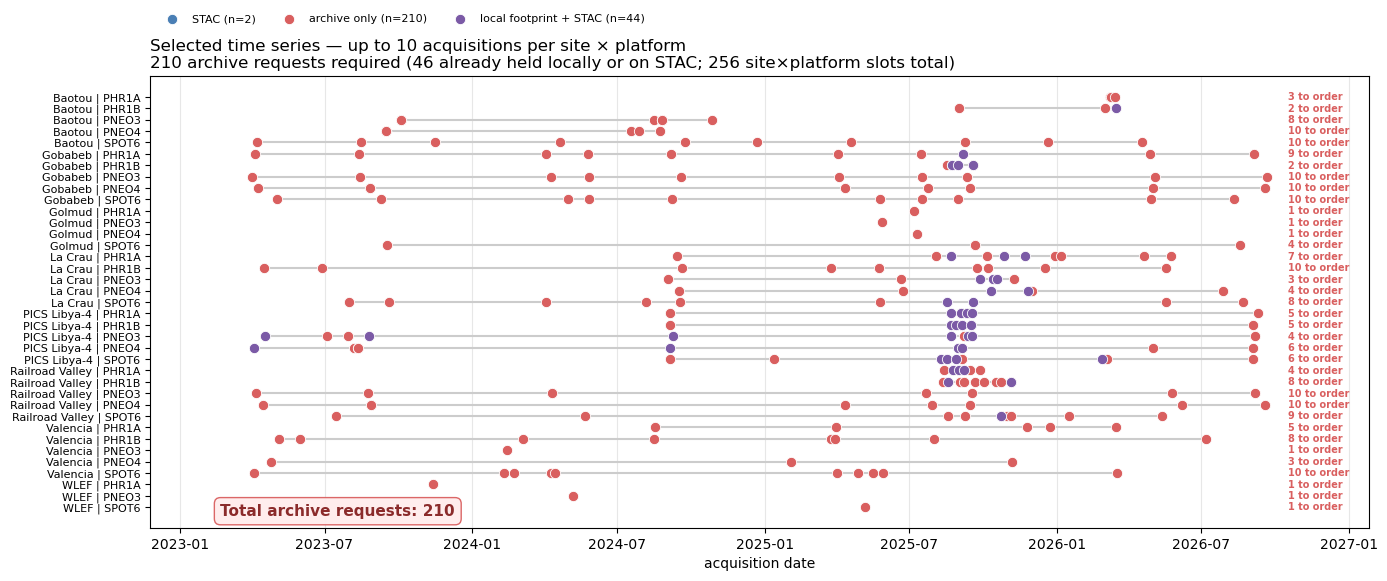

Archive requests (unique acquisitionIdentifier): 210


,n_to_order
site_platform,
Railroad Valley | PNEO3,10
Railroad Valley | PNEO4,10
Baotou | PNEO4,10
Baotou | SPOT6,10
Valencia | SPOT6,10
Gobabeb | PNEO3,10
Gobabeb | PNEO4,10
Gobabeb | SPOT6,10
La Crau | PHR1B,10


In [218]:
import matplotlib.pyplot as plt

# --- order accounting -----------------------------------------------------
to_order = best[best["Source"] == "archive only"]
n_order_rows   = len(to_order)                                  # site x platform slots
n_order_unique = to_order["acquisitionIdentifier"].nunique()     # actual vendor requests
n_held         = best["acquisitionIdentifier"].nunique() - n_order_unique
orders_per_lane = to_order.groupby("site_platform")["acquisitionIdentifier"].nunique()

lanes = sorted(best["site_platform"].unique())
ypos = {k: i for i, k in enumerate(lanes)}
colors = {"archive only": "#d95f5f", "STAC": "#4a7fb5",
          "local footprint": "#3f8f5a", "local footprint + STAC": "#7b5aa6"}

fig, ax = plt.subplots(figsize=(14, max(3.5, 0.16 * len(lanes))))

for k, i in ypos.items():
    s = best[best.site_platform == k]["_dt"]
    ax.plot([s.min(), s.max()], [i, i], color="#cccccc", lw=1.5, zorder=1)

for src, sub in best.groupby("Source", dropna=False):
    n_u = sub["acquisitionIdentifier"].nunique()
    ax.scatter(sub["_dt"], sub["site_platform"].map(ypos),
               c=colors.get(src, "grey"), s=55, label=f"{src} (n={n_u})",
               edgecolor="white", linewidth=0.6, zorder=3)

# per-lane order count on the right margin
xmax = best["_dt"].max()
pad = (xmax - best["_dt"].min()) * 0.02
for k, i in ypos.items():
    n = int(orders_per_lane.get(k, 0))
    ax.annotate(f"{n} to order" if n else "—",
                xy=(xmax + pad, i), va="center", ha="left", fontsize=7,
                color="#d95f5f" if n else "#999",
                weight="bold" if n else "normal",
                annotation_clip=False)

ax.set_yticks(range(len(lanes))); ax.set_yticklabels(lanes, fontsize=8)
ax.invert_yaxis(); ax.grid(axis="x", alpha=0.3); ax.set_axisbelow(True)
ax.set_xlabel("acquisition date")
ax.margins(x=0.10)

ax.set_title(f"Selected time series — up to {N_PER_GROUP} acquisitions per site × platform\n"
             f"{n_order_unique} archive requests required "
             f"({n_held} already held locally or on STAC; "
             f"{len(best)} site×platform slots total)",
             loc="left", fontsize=12)

ax.legend(fontsize=8, ncol=4, loc="upper left", bbox_to_anchor=(0, 1.16), frameon=False)

ax.annotate(f"Total archive requests: {n_order_unique}",
            xy=(0.25, 0.02), xycoords="axes fraction", ha="right", va="bottom",
            fontsize=11, weight="bold", color="#8b2b2b",
            bbox=dict(boxstyle="round,pad=0.4", facecolor="#ffecec",
                      edgecolor="#d95f5f", alpha=0.95))

plt.tight_layout(); plt.show()

# --- printed breakdown ----------------------------------------------------
print(f"Archive requests (unique acquisitionIdentifier): {n_order_unique}")
if n_order_rows != n_order_unique:
    print(f"  note: {n_order_rows} site×platform rows collapse to {n_order_unique} requests "
          f"({n_order_rows - n_order_unique} acquisitions serve >1 site)")
display(orders_per_lane.rename("n_to_order").to_frame()
        .sort_values("n_to_order", ascending=False))

## Here is the best subset (red dots) that we want to request from the archive

In [234]:
best_archive_only = best[best.Source == 'archive only']
best_archive_only.reset_index(drop=True, inplace=True)

out = Path('/home/pmontesa/CSDA_eval/summaries/request_airbus_20260929_best_subset_archive_only.csv')
best_archive_only.to_csv(out, index=False)
os.chmod(out, 0o644)

In [220]:
# Acquisition-level counts (archive_df is site-level, so dedupe on the identifier)
summary = (archive_df
    .pivot_table(index=["Site Name", "platform"], columns="Source",
                 values="acquisitionIdentifier", aggfunc="nunique", fill_value=0))

summary["Total"] = summary.sum(axis=1)
summary = summary.sort_values("Total", ascending=False)

display(summary)

Source                    STAC  archive only  local footprint + STAC  Total
Site Name       platform                                                   
Gobabeb         PNEO3        0           219                       1    220
                PNEO4        0           177                       2    179
Baotou          SPOT6        0           172                       1    173
Railroad Valley PNEO4        0            84                       1     85
                PNEO3        0            67                       2     69
La Crau         SPOT6        0            29                       6     35
Gobabeb         PHR1A        0            25                       3     28
PICS Libya-4    PNEO4        0            22                       5     27
Gobabeb         SPOT6        0            18                       2     20
Railroad Valley SPOT6        0            17                       3     20
Baotou          PNEO4        1            15                       0     16
                PNEO3        2            11                       0     13
La Crau         PHR1B        0            10                       3     13
PICS Libya-4    SPOT6        0             9                       4     13
Valencia        SPOT6        0            12                       0     12
Railroad Valley PHR1B        0             9                       3     12
PICS Libya-4    PNEO3        0             6                       6     12
La Crau         PHR1A        0             7                       3     10
PICS Libya-4    PHR1A        0             5                       4      9
                PHR1B        0             5                       4      9
Valencia        PHR1B        0             8                       0      8
Railroad Valley PHR1A        0             4                       3      7
Gobabeb         PHR1B        0             2                       4      6
La Crau         PNEO3        0             3                       3      6
                PNEO4        0             4                       2      6
Valencia        PHR1A        0             5                       0      5
Golmud          SPOT6        0             4                       0      4
Valencia        PNEO4        0             3                       0      3
Baotou          PHR1A        0             3                       0      3
                PHR1B        0             2                       1      3
Golmud          PNEO4        0             1                       0      1
Valencia        PNEO3        0             1                       0      1
Golmud          PNEO3        0             1                       0      1
                PHR1A        0             1                       0      1
WLEF            PHR1A        0             1                       0      1
                PNEO3        0             1                       0      1
                SPOT6        0             1                       0      1